# Hateful Memes Dataset Exploration & Visual Inspection
This notebook demonstrates loading the Hugging Face Hateful Memes dataset (`cs5242-hateful-memes/hateful-memes-data`), plotting meme images with text captions, and extracting ResNet50 & BERT feature representations.

In [1]:
from datasets import load_dataset

dataset = load_dataset(
    "cs5242-hateful-memes/hateful-memes-data"
)

print(dataset)

C:\mscgproject\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'text', 'label'],
        num_rows: 8500
    })
    dev_seen: Dataset({
        features: ['id', 'image', 'text', 'label'],
        num_rows: 398
    })
    dev_unseen: Dataset({
        features: ['id', 'image', 'text', 'label'],
        num_rows: 433
    })
    test_seen: Dataset({
        features: ['id', 'image', 'text', 'label'],
        num_rows: 1000
    })
    test_unseen: Dataset({
        features: ['id', 'image', 'text', 'label'],
        num_rows: 1593
    })
})


In [2]:
print(dataset["train"][0])

{'id': '42953', 'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=265x400 at 0x19F736A52B0>, 'text': 'its their character not their color that matters', 'label': 0}


ID: 42953
Text: its their character not their color that matters
Label: 0


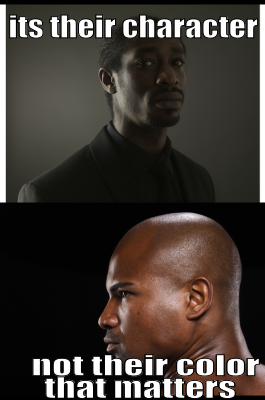

In [3]:
sample = dataset["train"][0]

print("ID:", sample["id"])
print("Text:", sample["text"])
print("Label:", sample["label"])

display(sample["image"])

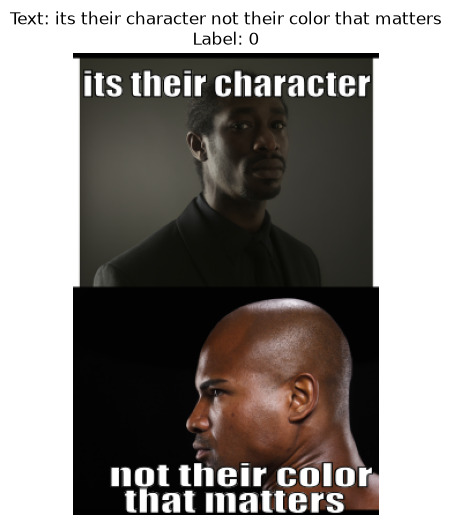

In [4]:
import matplotlib.pyplot as plt

sample = dataset["train"][0]

plt.figure(figsize=(8, 6))

plt.imshow(sample["image"])
plt.axis("off")

plt.title(
    f"Text: {sample['text']}\n"
    f"Label: {sample['label']}"
)

plt.show()

In [5]:
import pandas as pd

train_df = pd.DataFrame({
    "id": dataset["train"]["id"],
    "text": dataset["train"]["text"],
    "label": dataset["train"]["label"]
})

print(train_df.head())
print(train_df["label"].value_counts())

      id                                               text  label
0  42953   its their character not their color that matters      0
1  23058  don't be afraid to love again everyone is not ...      0
2  13894                           putting bows on your pet      0
3  37408  i love everything and everybody! except for sq...      0
4  82403  everybody loves chocolate chip cookies, even h...      0
label
0    5481
1    3019
Name: count, dtype: int64


In [6]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import torch
from models.cnn import model as cnn_model, transform, device as cnn_device

sample = dataset["train"][0]

image = sample["image"].convert("RGB")
image_tensor = transform(image)
image_tensor = image_tensor.unsqueeze(0).to(cnn_device)

with torch.no_grad():
    image_feature = cnn_model(image_tensor)

print("Extracted Image Feature Shape:", image_feature.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4367.28it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracted Image Feature Shape: torch.Size([1, 2048])


In [7]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import torch
from models.bert import model as bert_model, tokenizer, device as bert_device

text = dataset["train"][0]["text"]

inputs = tokenizer(
    text,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=128
)

inputs = {
    key: value.to(bert_device)
    for key, value in inputs.items()
}

with torch.no_grad():
    outputs = bert_model(**inputs)

text_feature = outputs.last_hidden_state[:, 0, :]

print("Extracted Text Feature Shape:", text_feature.shape)

Extracted Text Feature Shape: torch.Size([1, 768])
